In [3]:
import pandas as pd
import numpy as np

import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (Input,Conv1D,MaxPooling1D,UpSampling1D)

from tensorflow.keras.optimizers import Adam

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split

import matplotlib.pyplot as plt
from matplotlib import rcParams
from tensorflow.keras.layers import ZeroPadding1D

In [5]:
dataset_path = "UNSW-NB15_1.csv"
df = pd.read_csv(dataset_path, header = None,low_memory=False)

In [6]:
columns = [
    'srcip','sport','dstip','dsport','proto','state',
    'dur','sbytes','dbytes','sttl','dttl','sloss','dloss',
    'service','Sload','Dload','Spkts','Dpkts',
    'swin','dwin','stcpb','dtcpb','smeansz','dmeansz',
    'trans_depth','res_bdy_len','Sjit','Djit',
    'Stime','Ltime','Sintpkt','Dintpkt',
    'tcprtt','synack','ackdat','is_sm_ips_ports',
    'ct_state_ttl','ct_flw_http_mthd','is_ftp_login',
    'ct_ftp_cmd','ct_srv_src','ct_srv_dst',
    'ct_dst_ltm','ct_src_ltm',
    'ct_src_dport_ltm','ct_dst_sport_ltm',
    'ct_dst_src_ltm','attack_cat','label'
]
df.columns = columns

In [7]:
#uniquement les attaques reseaux sont gardés
X = df.drop(['attack_cat','label'],axis=1)

y = df['label']

In [8]:
#Encodage des variables catégorielles
categorical_features = X.select_dtypes( include=['object']).columns

encoder = LabelEncoder()

for col in categorical_features:
    X[col] = encoder.fit_transform(X[col].astype(str))

In [9]:
#Normalisation
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [10]:
X_cnn = np.expand_dims( X_scaled,axis=2)

In [11]:
X_cnn.shape

(700001, 47, 1)

In [12]:
# ===================================
# Sélection des données normales
# ===================================

X_normal = X_cnn[y == 0]

print("Données normales :", X_normal.shape)

Données normales : (677786, 47, 1)


In [28]:
# ===================================
# Train / Validation
# ===================================

X_train, X_val = train_test_split(X_normal,test_size=0.2,random_state=42)

print("Train :", X_train.shape)
print("Validation :", X_val.shape)

Train : (542228, 47, 1)
Validation : (135558, 47, 1)


In [33]:
# ===================================
# CNN Autoencoder
# ===================================

from tensorflow.keras.layers import (
    Input,
    Conv1D,
    MaxPooling1D,
    UpSampling1D,
    ZeroPadding1D,
    Cropping1D
)

from tensorflow.keras.models import Model


# Entrée

input_layer = Input(
    shape=(
        X_train.shape[1],
        1
    )
)


# ===================================
# Padding : 47 --> 48 features
# ===================================

x = ZeroPadding1D(
    padding=(0,1)
)(input_layer)


# ===================================
# Encodeur
# ===================================

x = Conv1D(
    filters=64,
    kernel_size=3,
    activation='relu',
    padding='same'
)(x)


x = MaxPooling1D(
    pool_size=2,
    padding='same'
)(x)


x = Conv1D(
    filters=32,
    kernel_size=3,
    activation='relu',
    padding='same'
)(x)


# Bottleneck

encoded = x


# ===================================
# Décodeur
# ===================================

x = Conv1D(
    filters=32,
    kernel_size=3,
    activation='relu',
    padding='same'
)(encoded)


x = UpSampling1D(
    size=2
)(x)


x = Conv1D(
    filters=64,
    kernel_size=3,
    activation='relu',
    padding='same'
)(x)


# ===================================
# Suppression du padding ajouté
# 48 --> 47 features
# ===================================

x = Cropping1D(
    cropping=(0,1)
)(x)


# Reconstruction finale

output_layer = Conv1D(
    filters=1,
    kernel_size=3,
    activation='linear',
    padding='same'
)(x)



# Création modèle

cnn_autoencoder = Model(
    input_layer,
    output_layer
)


cnn_autoencoder.summary()

Model: "model_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_4 (InputLayer)        [(None, 47, 1)]           0         
                                                                 
 zero_padding1d_1 (ZeroPadd  (None, 48, 1)             0         
 ing1D)                                                          
                                                                 
 conv1d_11 (Conv1D)          (None, 48, 64)            256       
                                                                 
 max_pooling1d_2 (MaxPoolin  (None, 24, 64)            0         
 g1D)                                                            
                                                                 
 conv1d_12 (Conv1D)          (None, 24, 32)            6176      
                                                                 
 conv1d_13 (Conv1D)          (None, 24, 32)            3104

In [34]:
# ===================================
# Compilation
# ===================================

cnn_autoencoder.compile( optimizer=Adam( learning_rate=0.001),loss='mse')

In [35]:
# ===================================
# Entraînement
# ===================================

history = cnn_autoencoder.fit(
    X_train,
    X_train,
    epochs=50,
    batch_size=128,
    validation_data=(
        X_val,
        X_val
    )
)

Epoch 1/50

4237/4237 [==============================] - 66s 15ms/step - loss: 0.0090 - val_loss: 0.0028
Epoch 2/50
4237/4237 [==============================] - 67s 16ms/step - loss: 0.0067 - val_loss: 0.0179
Epoch 3/50
4237/4237 [==============================] - 93s 22ms/step - loss: 0.0021 - val_loss: 0.0069
Epoch 4/50
4237/4237 [==============================] - 66s 15ms/step - loss: 0.0015 - val_loss: 4.9781e-04
Epoch 5/50
4237/4237 [==============================] - 67s 16ms/step - loss: 8.7907e-04 - val_loss: 5.3358e-04
Epoch 6/50
4237/4237 [==============================] - 66s 16ms/step - loss: 0.0014 - val_loss: 3.9261e-04
Epoch 7/50
4237/4237 [==============================] - 63s 15ms/step - loss: 0.0014 - val_loss: 5.1274e-04
Epoch 8/50
4237/4237 [==============================] - 64s 15ms/step - loss: 6.3248e-04 - val_loss: 1.8874e-04
Epoch 9/50
4237/4237 [==============================] - 64s 15ms/step - loss: 6.6280e-04 - val_loss: 2.9518e-04
Epoch 10/50
4237/4237 [====

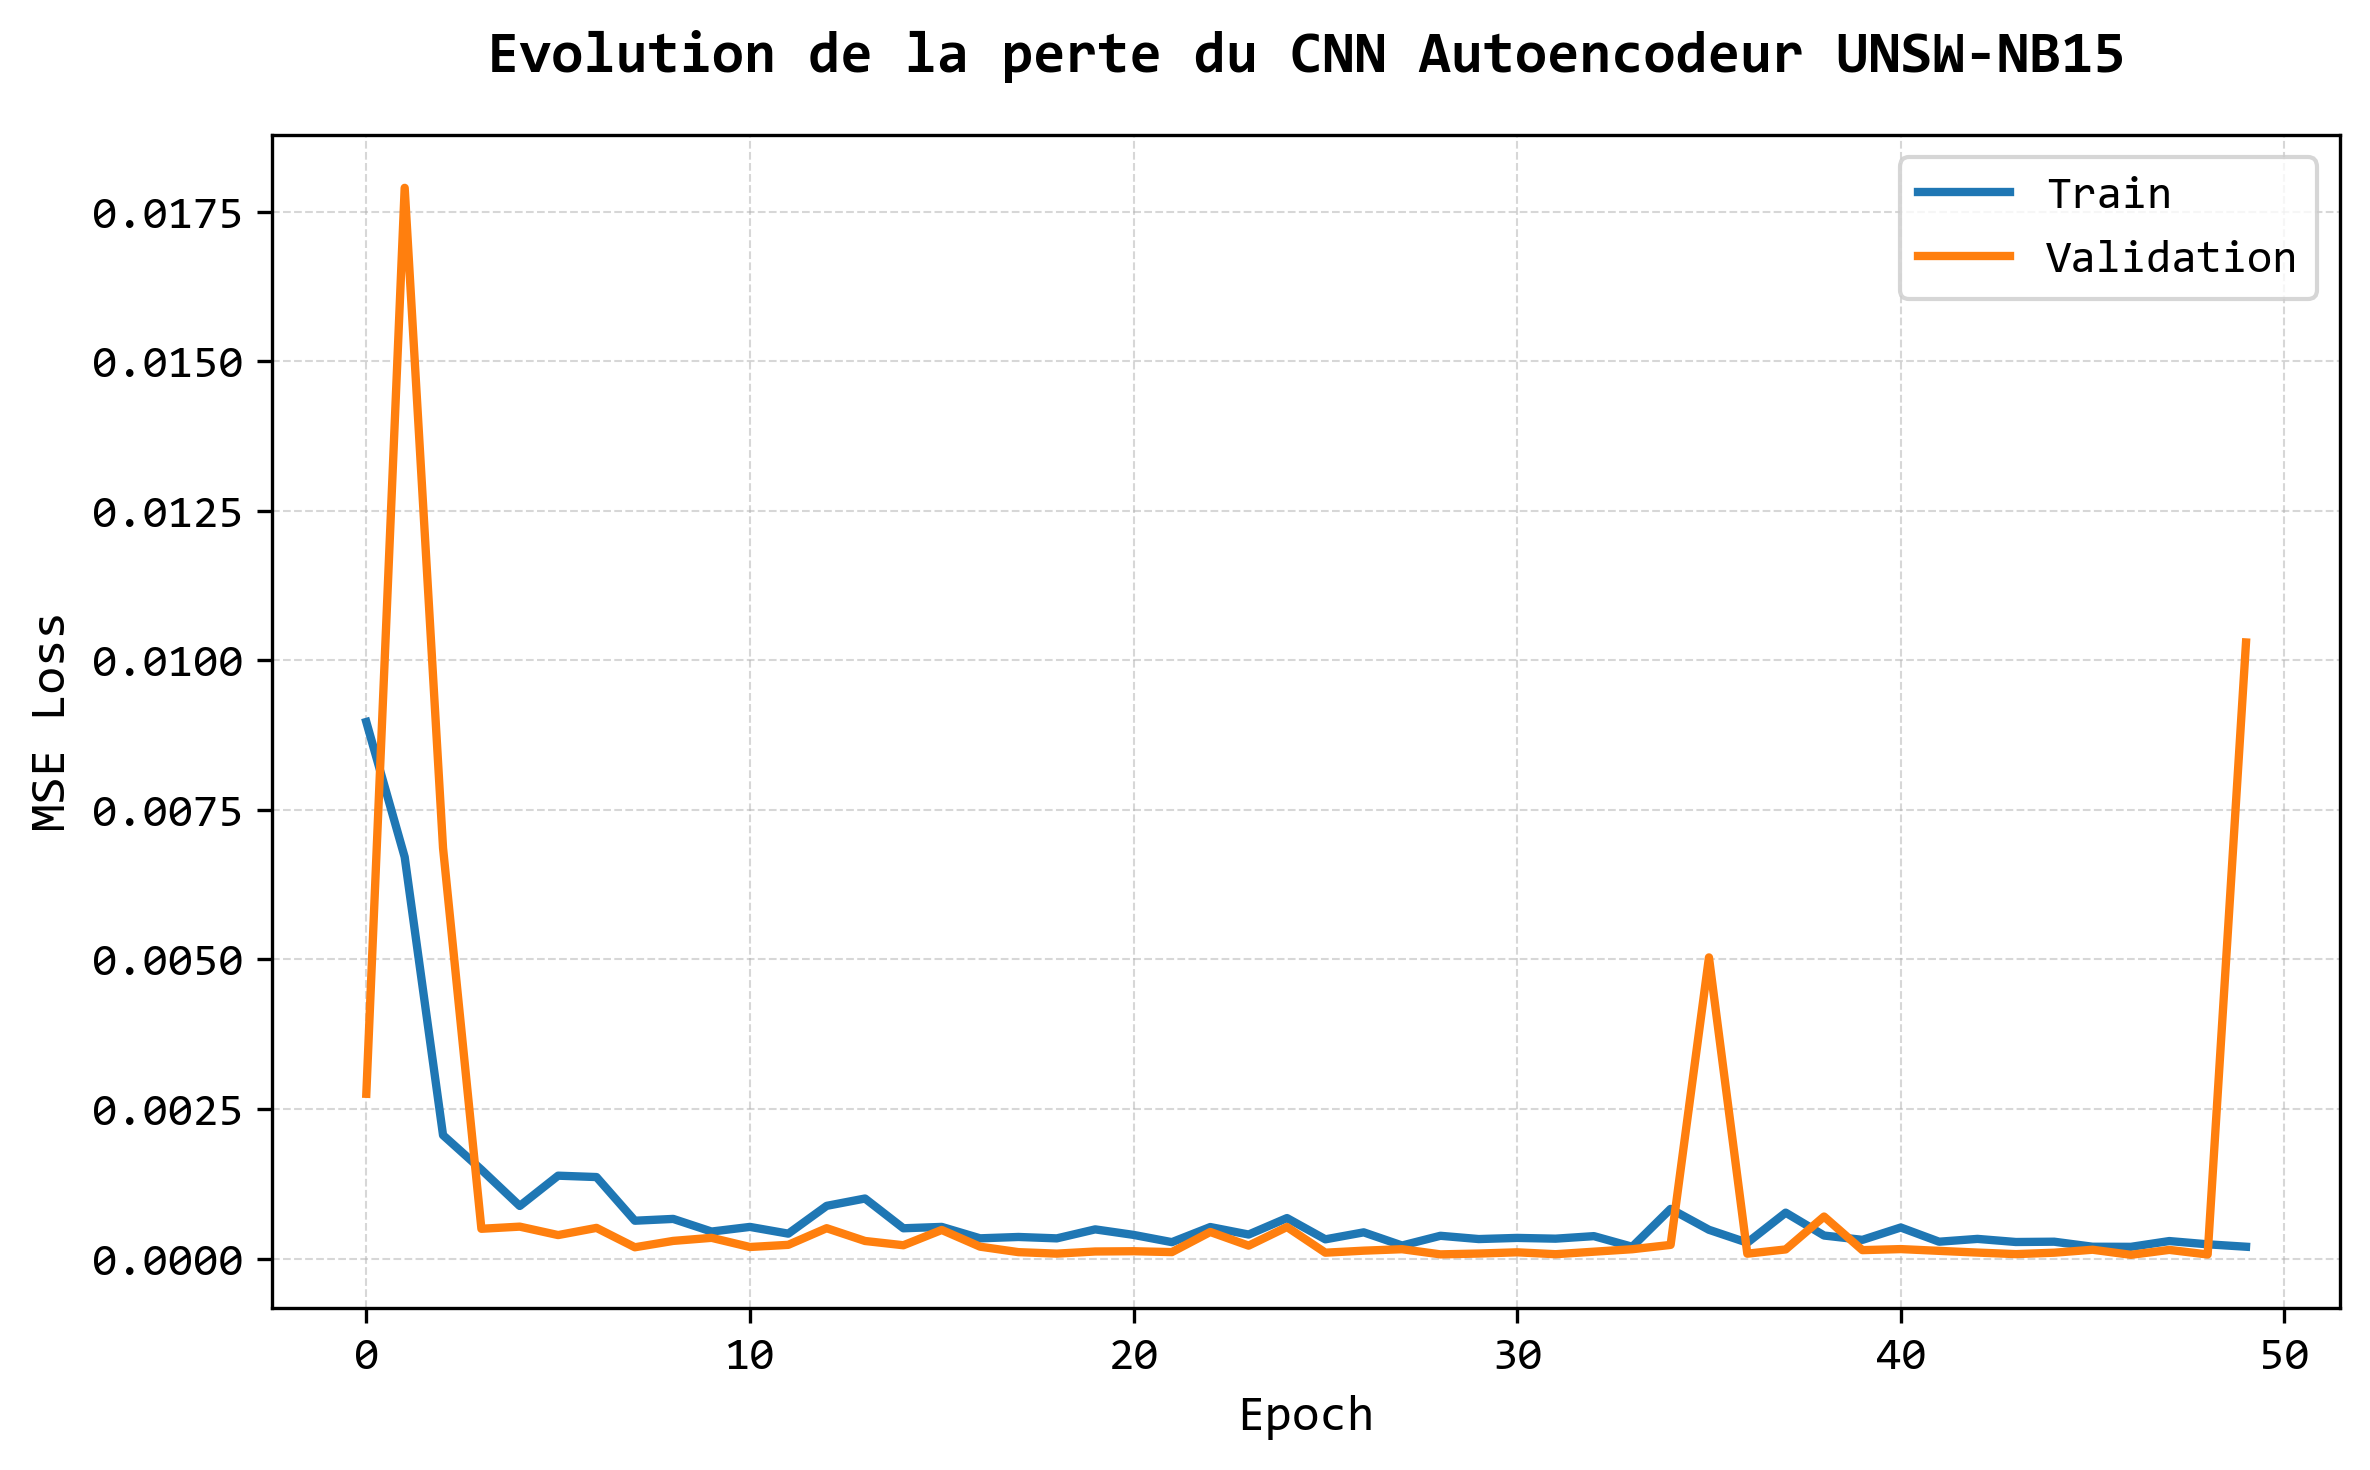

In [70]:
import matplotlib.pyplot as plt
from matplotlib import rcParams


# ==========================================
# Police globale Consolas
# ==========================================

rcParams['font.family'] = 'Consolas'


# ==========================================
# Figure
# ==========================================

plt.figure(
    figsize=(8,5),
    dpi=300
)


# ==========================================
# Courbe entraînement
# ==========================================

plt.plot(
    history.history['loss'],
    label='Train',
    linewidth=2
)


# ==========================================
# Courbe validation
# ==========================================

plt.plot(
    history.history['val_loss'],
    label='Validation',
    linewidth=2
)



# ==========================================
# Labels axes
# ==========================================

plt.xlabel(
    "Epoch",
    fontsize=12,
    fontfamily="Consolas"
)


plt.ylabel(
    "MSE Loss",
    fontsize=12,
    fontfamily="Consolas"
)



# ==========================================
# Titre
# ==========================================

plt.title(
    "Evolution de la perte du CNN Autoencodeur UNSW-NB15",
    fontsize=14,
    fontweight="bold",
    fontfamily="Consolas",
    pad=15
)



# ==========================================
# Légende
# ==========================================

plt.legend(
    fontsize=11
)



# ==========================================
# Personnalisation ticks
# ==========================================

plt.xticks(
    fontsize=11,
    fontfamily="Consolas"
)


plt.yticks(
    fontsize=11,
    fontfamily="Consolas"
)



# ==========================================
# Grille
# ==========================================

plt.grid(
    True,
    linestyle="--",
    linewidth=0.5,
    alpha=0.5
)



# ==========================================
# Ajustement
# ==========================================

plt.tight_layout()



# ==========================================
# Sauvegarde PNG pour LaTeX
# ==========================================

plt.savefig(
    "courbe_loss_cnn_autoencodeur_unsw_nb15.png",
    format="png",
    dpi=300,
    bbox_inches="tight"
)



plt.show()

In [71]:
X_cnn
y

0         0
1         0
2         0
3         0
4         0
         ..
699996    0
699997    0
699998    0
699999    0
700000    0
Name: label, Length: 700001, dtype: int64

In [13]:
# ===================================
# Données de test pour détection
# ===================================

X_test = X_cnn

y_test = y.values


print(X_test.shape)
print(y_test.shape)

(700001, 47, 1)
(700001,)


In [73]:
# ===================================
# Reconstruction
# ===================================

X_pred = cnn_autoencoder.predict( X_test)

21876/21876 [==============================] - 84s 4ms/step


In [74]:
print(X_pred.shape)

(700001, 47, 1)


In [76]:
# ===================================
# Erreur MSE par échantillon
# ===================================

mse_error = np.mean(
    np.power(
        X_test - X_pred,
        2
    ),
    axis=(1,2)
)

In [77]:
mse_error.shape

(700001,)

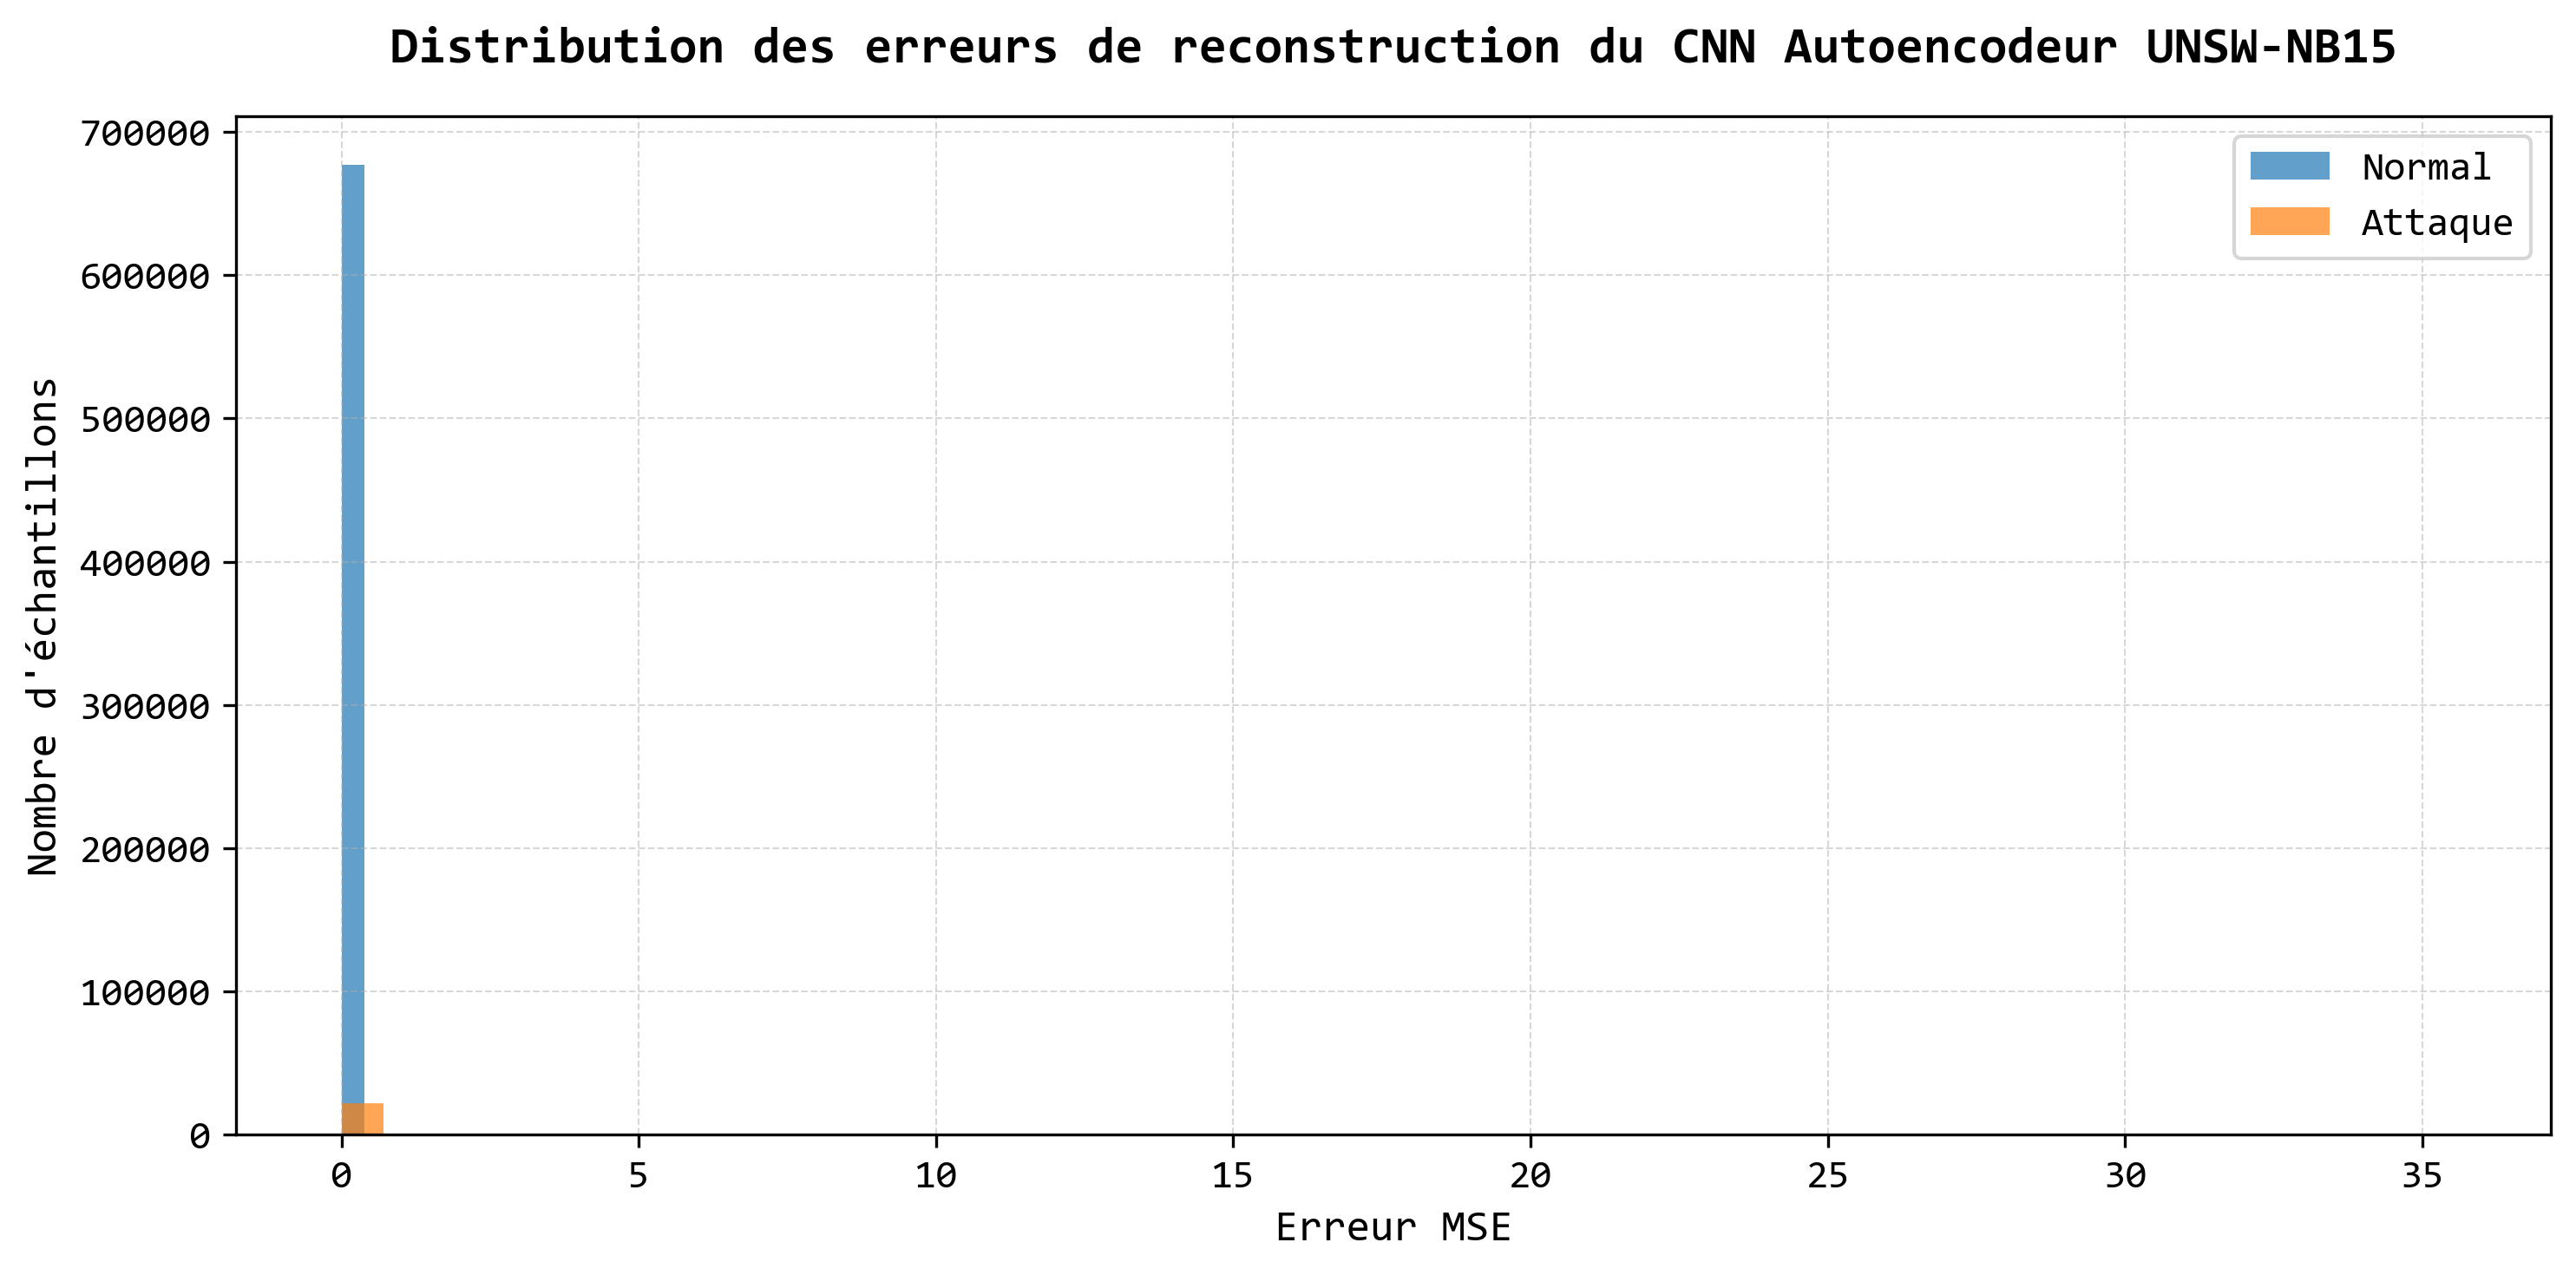

In [78]:
import matplotlib.pyplot as plt
from matplotlib import rcParams


# ==========================================
# Police globale Consolas
# ==========================================

rcParams['font.family'] = 'Consolas'


# ==========================================
# Création de la figure
# ==========================================

plt.figure(
    figsize=(10,5),
    dpi=300
)


# ==========================================
# Distribution erreur reconstruction normale
# ==========================================

plt.hist(
    mse_error[y_test == 0],
    bins=50,
    alpha=0.7,
    label="Normal"
)



# ==========================================
# Distribution erreur reconstruction attaque
# ==========================================

plt.hist(
    mse_error[y_test == 1],
    bins=50,
    alpha=0.7,
    label="Attaque"
)



# ==========================================
# Labels des axes
# ==========================================

plt.xlabel(
    "Erreur MSE",
    fontsize=12,
    fontfamily="Consolas"
)


plt.ylabel(
    "Nombre d'échantillons",
    fontsize=12,
    fontfamily="Consolas"
)



# ==========================================
# Titre
# ==========================================

plt.title(
    "Distribution des erreurs de reconstruction du CNN Autoencodeur UNSW-NB15",
    fontsize=14,
    fontweight="bold",
    fontfamily="Consolas",
    pad=15
)



# ==========================================
# Légende
# ==========================================

plt.legend(
    fontsize=11
)



# ==========================================
# Personnalisation ticks
# ==========================================

plt.xticks(
    fontsize=11,
    fontfamily="Consolas"
)


plt.yticks(
    fontsize=11,
    fontfamily="Consolas"
)



# ==========================================
# Grille
# ==========================================

plt.grid(
    True,
    linestyle="--",
    linewidth=0.5,
    alpha=0.5
)



# ==========================================
# Ajustement
# ==========================================

plt.tight_layout()



# ==========================================
# Sauvegarde PNG haute résolution
# ==========================================

plt.savefig(
    "distribution_erreur_mse_cnn_autoencodeur_unsw_nb15.png",
    format="png",
    dpi=300,
    bbox_inches="tight"
)



plt.show()

In [79]:
# ===================================
# Calcul du seuil
# ===================================

normal_error = mse_error[y_test == 0]


threshold = np.percentile(
    normal_error,
    95
)


print(
    "Seuil d'anomalie :",
    threshold
)

Seuil d'anomalie : 0.033793210043287614


In [80]:
# ===================================
# Classification
# ===================================

y_pred = np.where(mse_error > threshold,1,0)

In [81]:
print(
    "Normaux détectés :",
    np.sum(y_pred == 0)
)


print(
    "Attaques détectées :",
    np.sum(y_pred == 1)
)

Normaux détectés : 657118
Attaques détectées : 42883


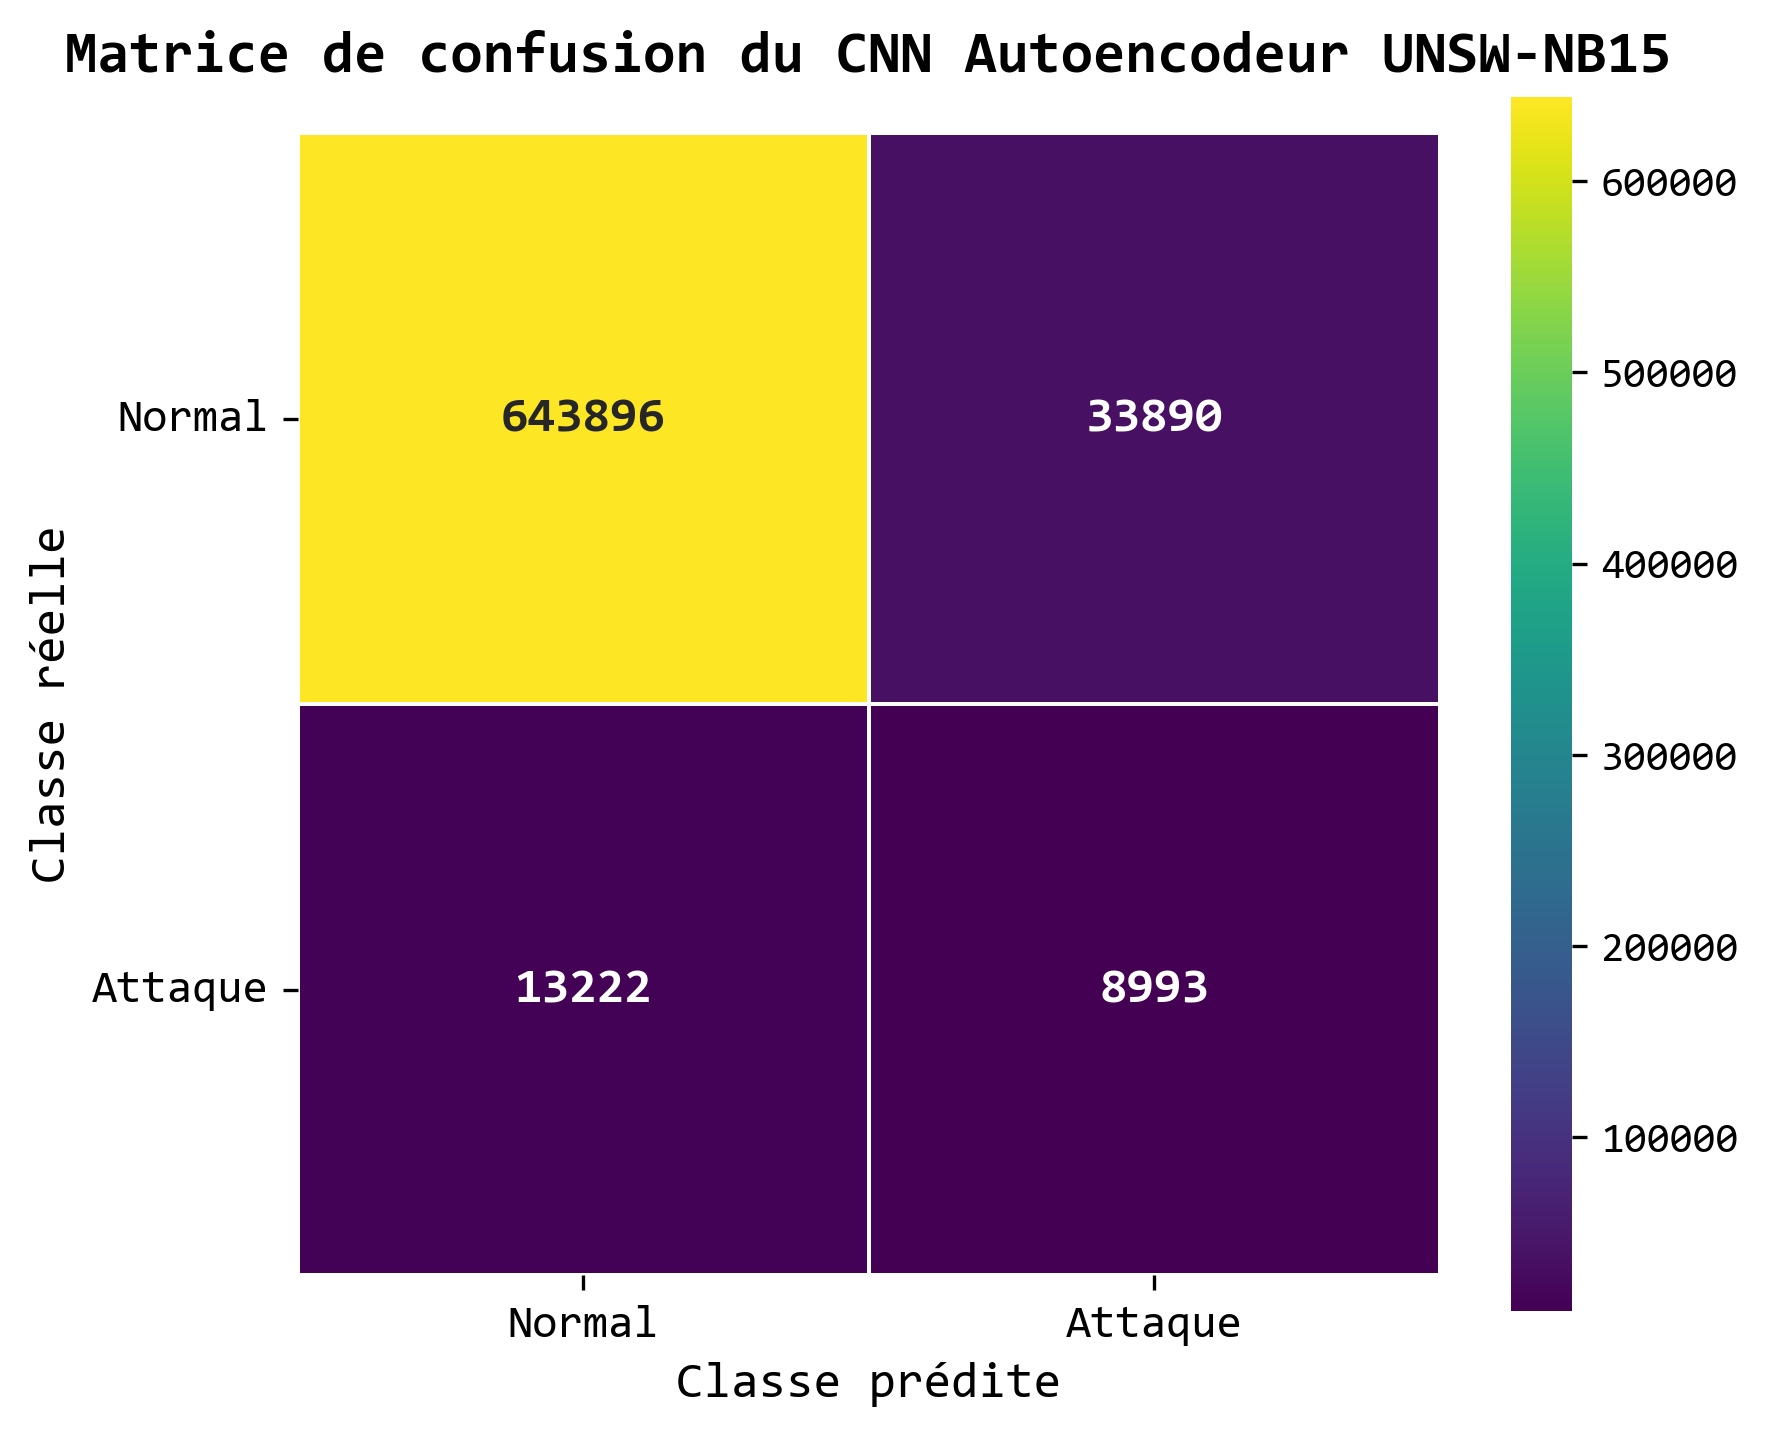

In [82]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib import rcParams


# ==========================================
# Police globale Consolas
# ==========================================

rcParams['font.family'] = 'Consolas'


# ==========================================
# Calcul matrice de confusion
# ==========================================

cm = confusion_matrix(
    y_test,
    y_pred
)



# ==========================================
# Création figure
# ==========================================

plt.figure(
    figsize=(6,5),
    dpi=300
)



# ==========================================
# Heatmap
# ==========================================

ax = sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="viridis",
    linewidths=0.5,
    square=True,
    cbar=True,
    annot_kws={
        "fontsize":12,
        "fontfamily":"Consolas",
        "fontweight":"bold"
    }
)


# ==========================================
# Labels axes
# ==========================================

plt.xlabel(
    "Classe prédite",
    fontsize=12,
    fontfamily="Consolas"
)


plt.ylabel(
    "Classe réelle",
    fontsize=12,
    fontfamily="Consolas"
)



# ==========================================
# Titre
# ==========================================

plt.title(
    "Matrice de confusion du CNN Autoencodeur UNSW-NB15",
    fontsize=14,
    fontweight="bold",
    fontfamily="Consolas",
    pad=15
)



# ==========================================
# Noms des classes
# ==========================================

ax.set_xticklabels(
    ["Normal", "Attaque"],
    fontsize=11,
    fontfamily="Consolas"
)


ax.set_yticklabels(
    ["Normal", "Attaque"],
    fontsize=11,
    fontfamily="Consolas",
    rotation=0
)



# ==========================================
# Barre de couleur
# ==========================================

cbar = ax.collections[0].colorbar

cbar.ax.tick_params(
    labelsize=10
)


for label in cbar.ax.get_yticklabels():
    label.set_fontname("Consolas")



# ==========================================
# Ajustement
# ==========================================

plt.tight_layout()



# ==========================================
# Sauvegarde PNG LaTeX
# ==========================================

plt.savefig(
    "matrice_confusion_cnn_autoencodeur_unsw_nb15.png",
    format="png",
    dpi=300,
    bbox_inches="tight"
)



plt.show()

In [83]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

In [84]:
accuracy = accuracy_score(
    y_test,
    y_pred
)

print(
    "Accuracy :",
    accuracy
)

Accuracy : 0.9326972390039443


In [85]:
precision = precision_score(
    y_test,
    y_pred
)

print(
    "Precision :",
    precision
)

Precision : 0.20971014154793274


In [86]:
recall = recall_score(
    y_test,
    y_pred
)

print(
    "Recall :",
    recall
)

Recall : 0.4048165653837497


In [87]:
f1 = f1_score(
    y_test,
    y_pred
)

print(
    "F1-score :",
    f1
)

F1-score : 0.2762911302958616


In [88]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "Normal",
            "Attack"
        ]
    )
)

              precision    recall  f1-score   support

      Normal       0.98      0.95      0.96    677786
      Attack       0.21      0.40      0.28     22215

    accuracy                           0.93    700001
   macro avg       0.59      0.68      0.62    700001
weighted avg       0.96      0.93      0.94    700001



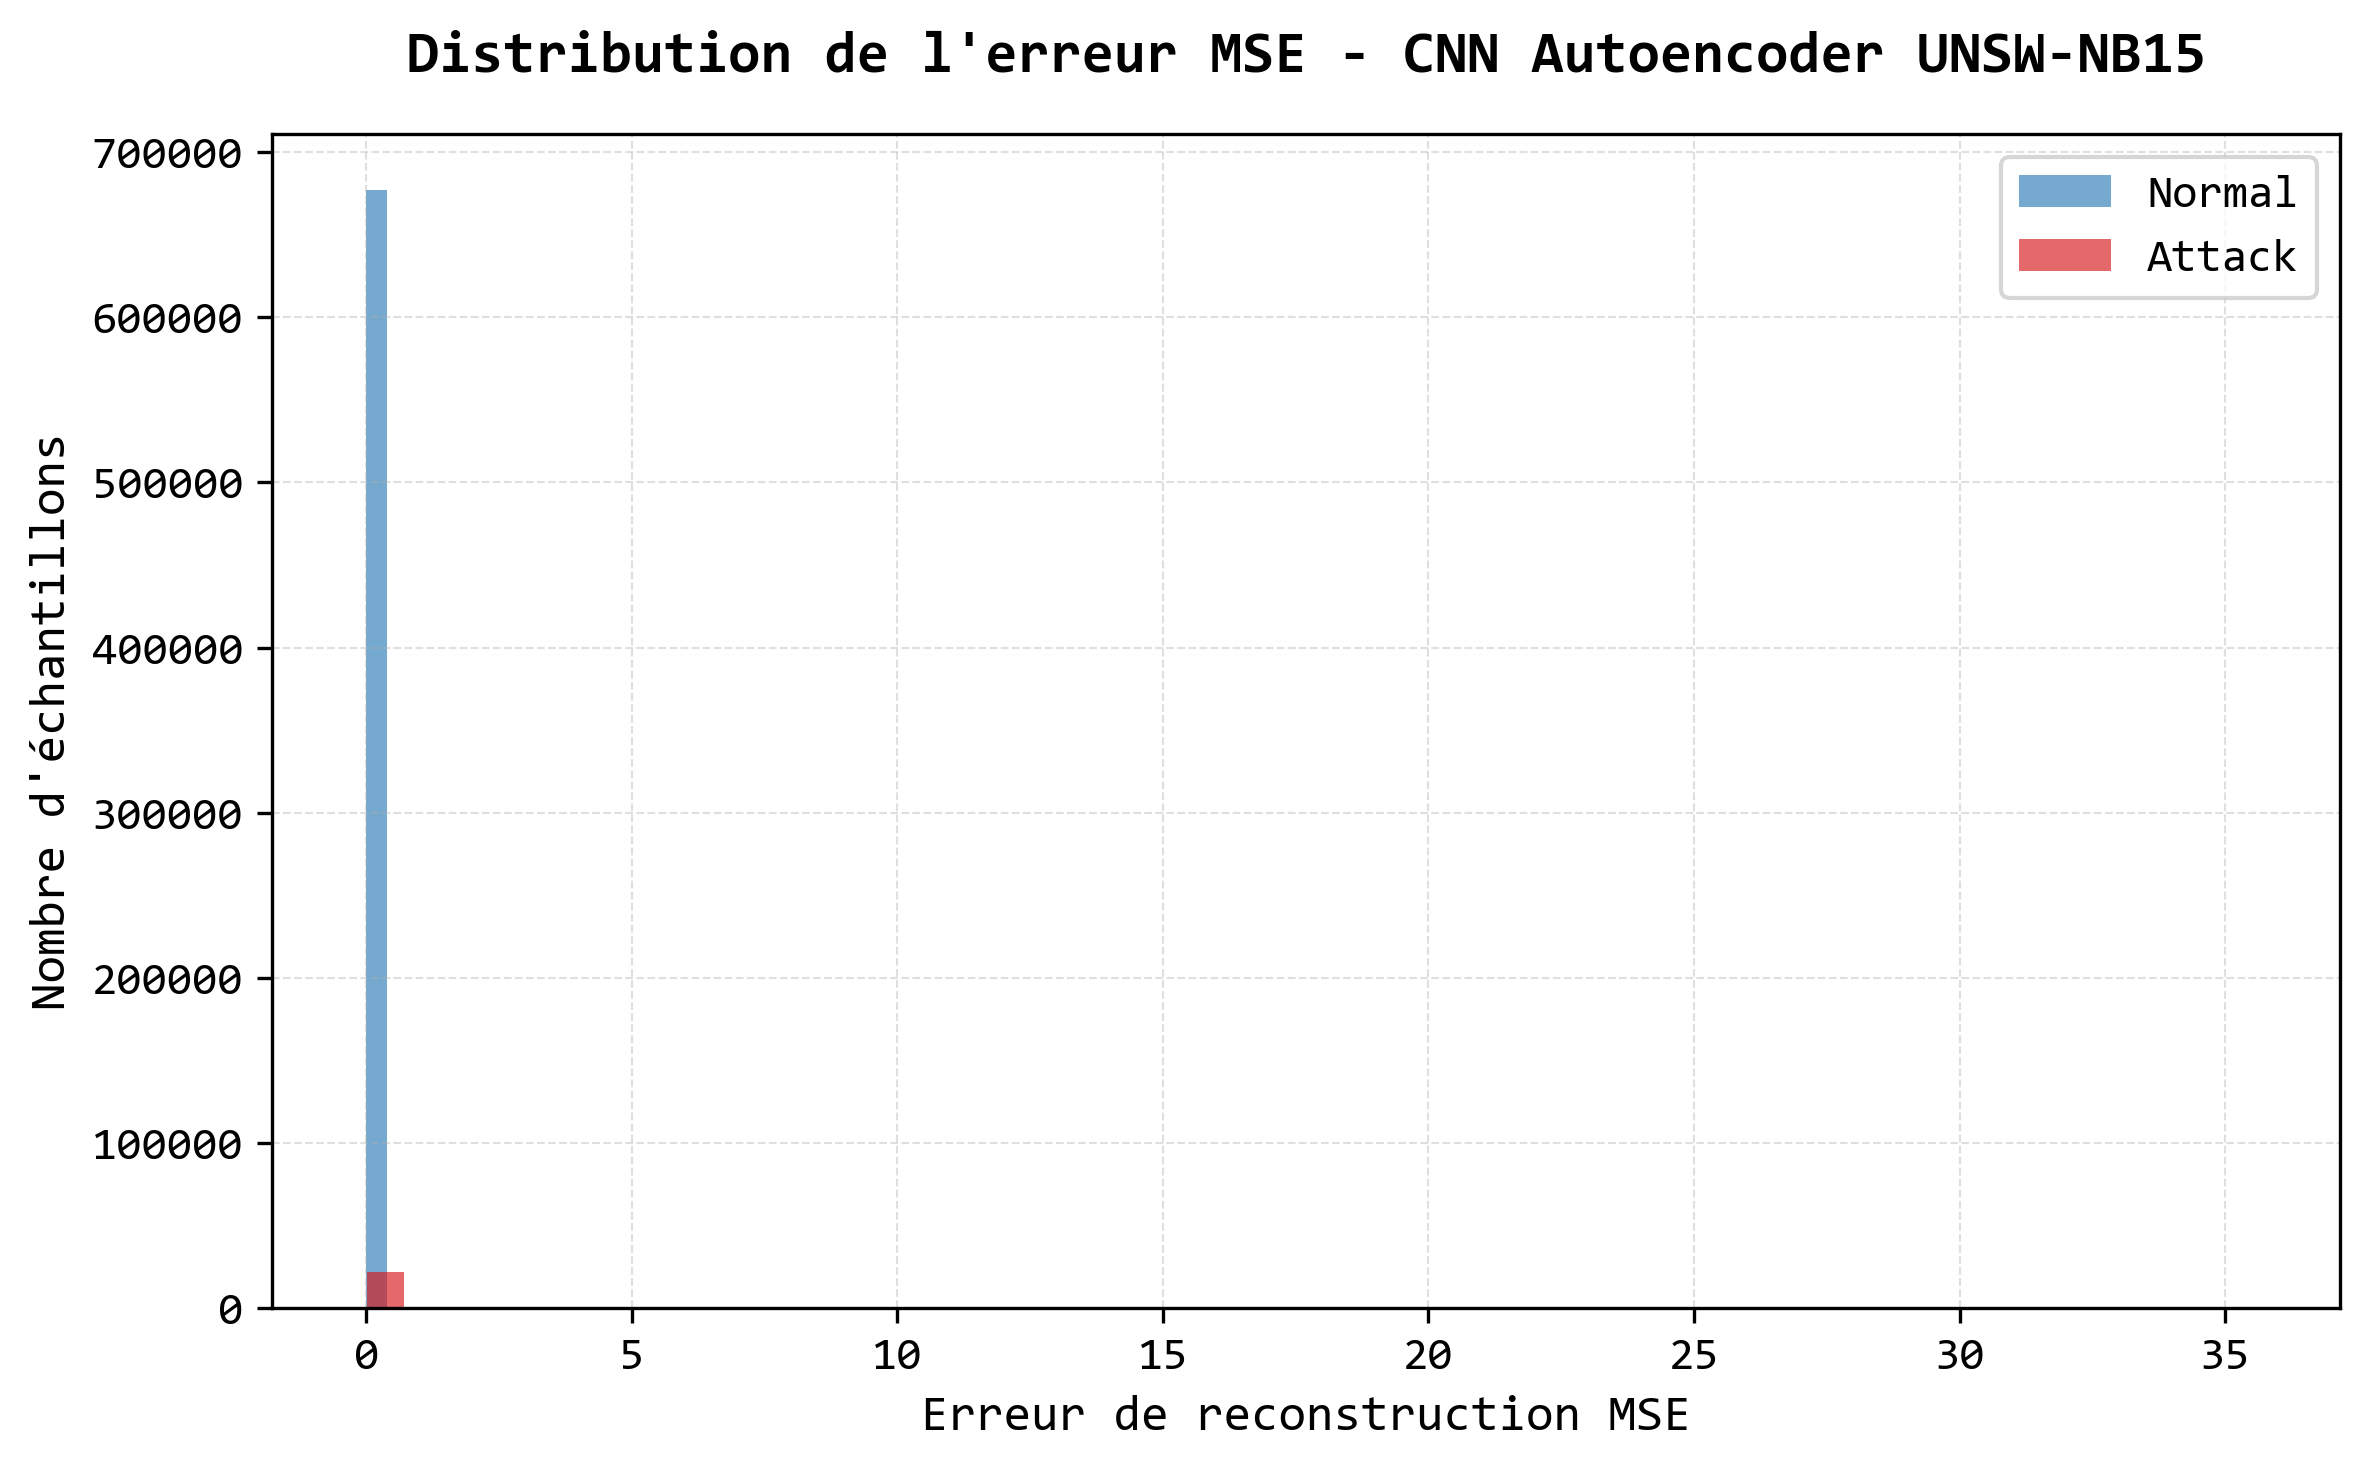

In [89]:
import matplotlib.pyplot as plt
from matplotlib import rcParams


# ==========================================
# Police globale Consolas
# ==========================================

rcParams['font.family'] = 'Consolas'


# ==========================================
# Distribution erreur MSE CNN Autoencoder
# ==========================================

plt.figure(
    figsize=(8,5),
    dpi=300
)


# Couleur trafic normal

plt.hist(
    mse_error[y_test == 0],
    bins=50,
    alpha=0.65,
    label="Normal",
    color="#2C7BB6"
)



# Couleur attaques

plt.hist(
    mse_error[y_test == 1],
    bins=50,
    alpha=0.65,
    label="Attack",
    color="#D7191C"
)



# ==========================================
# Labels axes
# ==========================================

plt.xlabel(
    "Erreur de reconstruction MSE",
    fontsize=12,
    fontfamily="Consolas"
)


plt.ylabel(
    "Nombre d'échantillons",
    fontsize=12,
    fontfamily="Consolas"
)



# ==========================================
# Titre
# ==========================================

plt.title(
    "Distribution de l'erreur MSE - CNN Autoencoder UNSW-NB15",
    fontsize=14,
    fontweight="bold",
    fontfamily="Consolas",
    pad=15
)



# ==========================================
# Légende
# ==========================================

plt.legend(
    fontsize=11
)



# ==========================================
# Axes
# ==========================================

plt.xticks(
    fontsize=11,
    fontfamily="Consolas"
)


plt.yticks(
    fontsize=11,
    fontfamily="Consolas"
)



# ==========================================
# Grille
# ==========================================

plt.grid(
    True,
    linestyle="--",
    linewidth=0.5,
    alpha=0.4
)



plt.tight_layout()



# ==========================================
# Sauvegarde LaTeX
# ==========================================

plt.savefig(
    "distribution_erreur_mse_cnn_autoencoder_unsw_nb15.png",
    dpi=300,
    bbox_inches="tight",
    format="png"
)



plt.show()

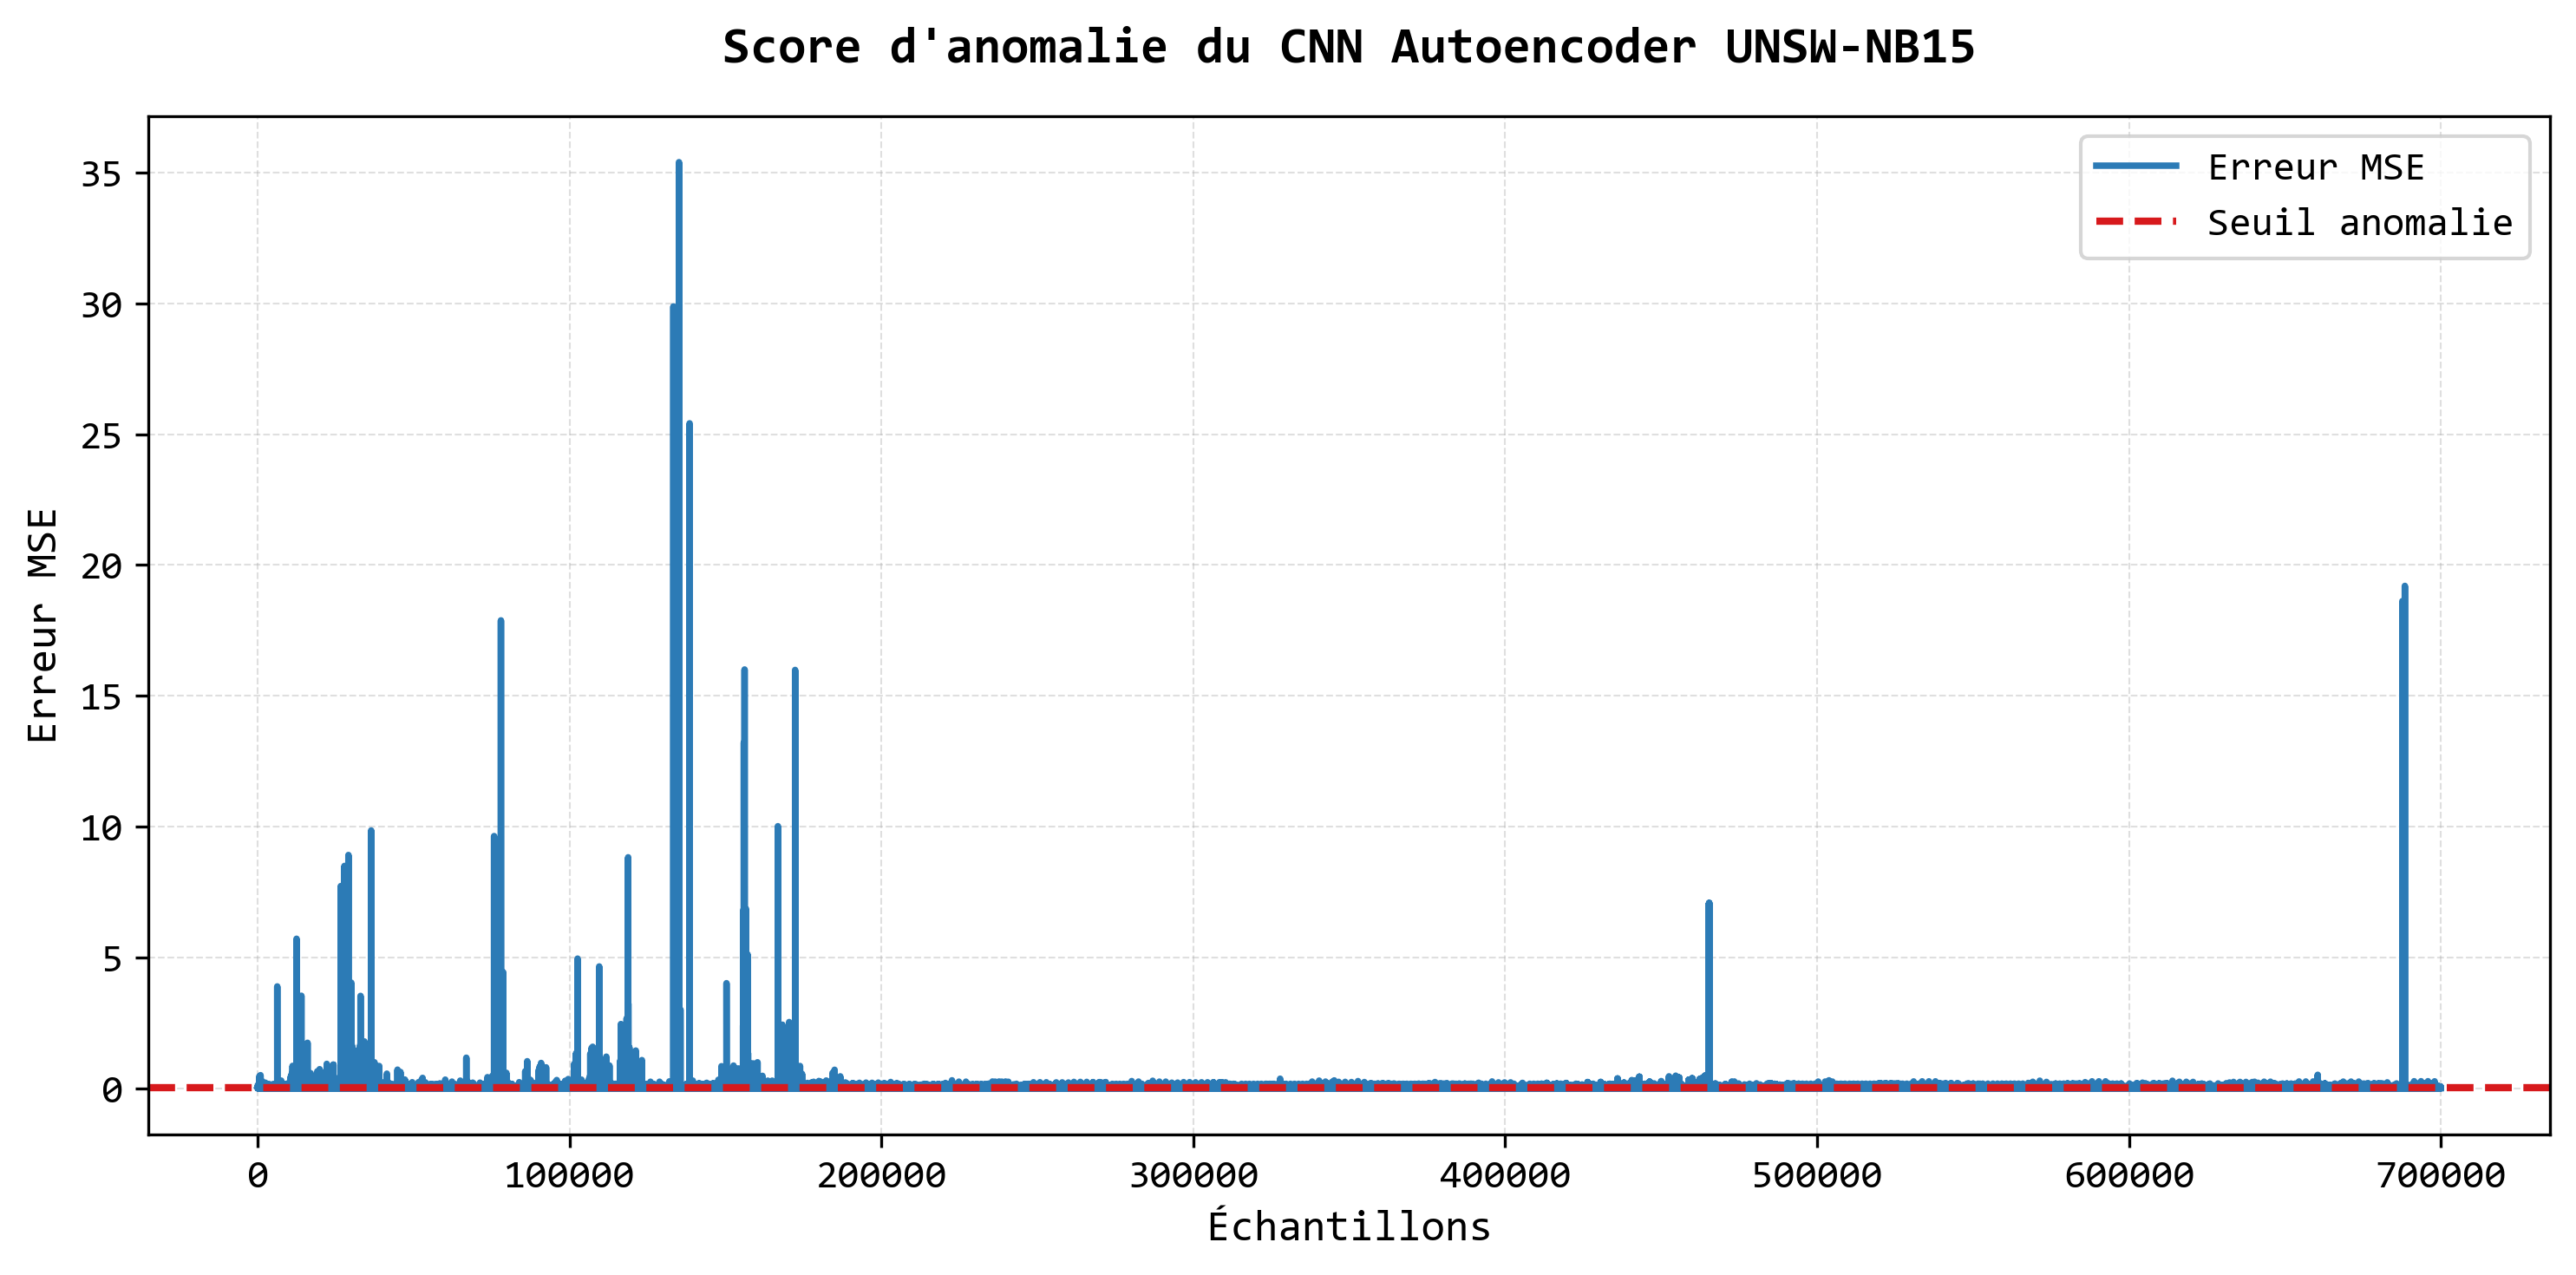

In [90]:
import matplotlib.pyplot as plt
from matplotlib import rcParams


# ==========================================
# Police globale Consolas
# ==========================================

rcParams['font.family'] = 'Consolas'



# ==========================================
# Visualisation seuil CNN Autoencoder
# ==========================================

plt.figure(
    figsize=(10,5),
    dpi=300
)



# ==========================================
# Courbe erreur MSE
# ==========================================

plt.plot(
    mse_error,
    label="Erreur MSE",
    linewidth=1.8,
    color="#2C7BB6"
)



# ==========================================
# Ligne seuil anomalie
# ==========================================

plt.axhline(
    y=threshold,
    linestyle="--",
    linewidth=2,
    label="Seuil anomalie",
    color="#D7191C"
)



# ==========================================
# Labels axes
# ==========================================

plt.xlabel(
    "Échantillons",
    fontsize=12,
    fontfamily="Consolas"
)


plt.ylabel(
    "Erreur MSE",
    fontsize=12,
    fontfamily="Consolas"
)



# ==========================================
# Titre
# ==========================================

plt.title(
    "Score d'anomalie du CNN Autoencoder UNSW-NB15",
    fontsize=14,
    fontweight="bold",
    fontfamily="Consolas",
    pad=15
)



# ==========================================
# Légende
# ==========================================

plt.legend(
    fontsize=11
)



# ==========================================
# Personnalisation ticks
# ==========================================

plt.xticks(
    fontsize=11,
    fontfamily="Consolas"
)


plt.yticks(
    fontsize=11,
    fontfamily="Consolas"
)



# ==========================================
# Grille
# ==========================================

plt.grid(
    True,
    linestyle="--",
    linewidth=0.5,
    alpha=0.4
)



# ==========================================
# Ajustement
# ==========================================

plt.tight_layout()



# ==========================================
# Sauvegarde PNG pour LaTeX
# ==========================================

plt.savefig(
    "score_anomalie_cnn_autoencoder_unsw_nb15.png",
    format="png",
    dpi=300,
    bbox_inches="tight"
)



plt.show()

In [91]:
from sklearn.metrics import recall_score


detection_rate = recall_score(
    y_test,
    y_pred
)


print(
    "Detection Rate :",
    detection_rate
)

Detection Rate : 0.4048165653837497


In [92]:
from sklearn.metrics import confusion_matrix


tn, fp, fn, tp = confusion_matrix(
    y_test,
    y_pred
).ravel()


fpr = fp / (fp + tn)


print(
    "False Positive Rate :",
    fpr
)

False Positive Rate : 0.05000103277435651


In [93]:
# ===================================
# Résumé performances CNN
# ===================================

results_cnn = pd.DataFrame({

    "Model":[
        "CNN Autoencoder"
    ],

    "Accuracy":[
        accuracy
    ],

    "Precision":[
        precision
    ],

    "Recall":[
        recall
    ],

    "F1-score":[
        f1
    ],

    "Detection Rate":[
        detection_rate
    ],

    "FPR":[
        fpr
    ]

})


results_cnn

,Model,Accuracy,Precision,Recall,F1-score,Detection Rate,FPR
0,CNN Autoencoder,0.932697,0.20971,0.404817,0.276291,0.404817,0.050001


In [95]:
# ===================================
# Sauvegarde
# ===================================

cnn_autoencoder.save("CNN_Autoencoder_UNSW15.h5")
print("Résultats exportés")

Résultats exportés


C:\Users\Taka\anaconda3\envs\tensorflow\lib\site-packages\keras\src\engine\training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(




2735/2735 [==============================] - 23s 8ms/step
Observations normales : 677,786
Observations attaques : 22,215
Seuil historique P95 : 0.0337932100


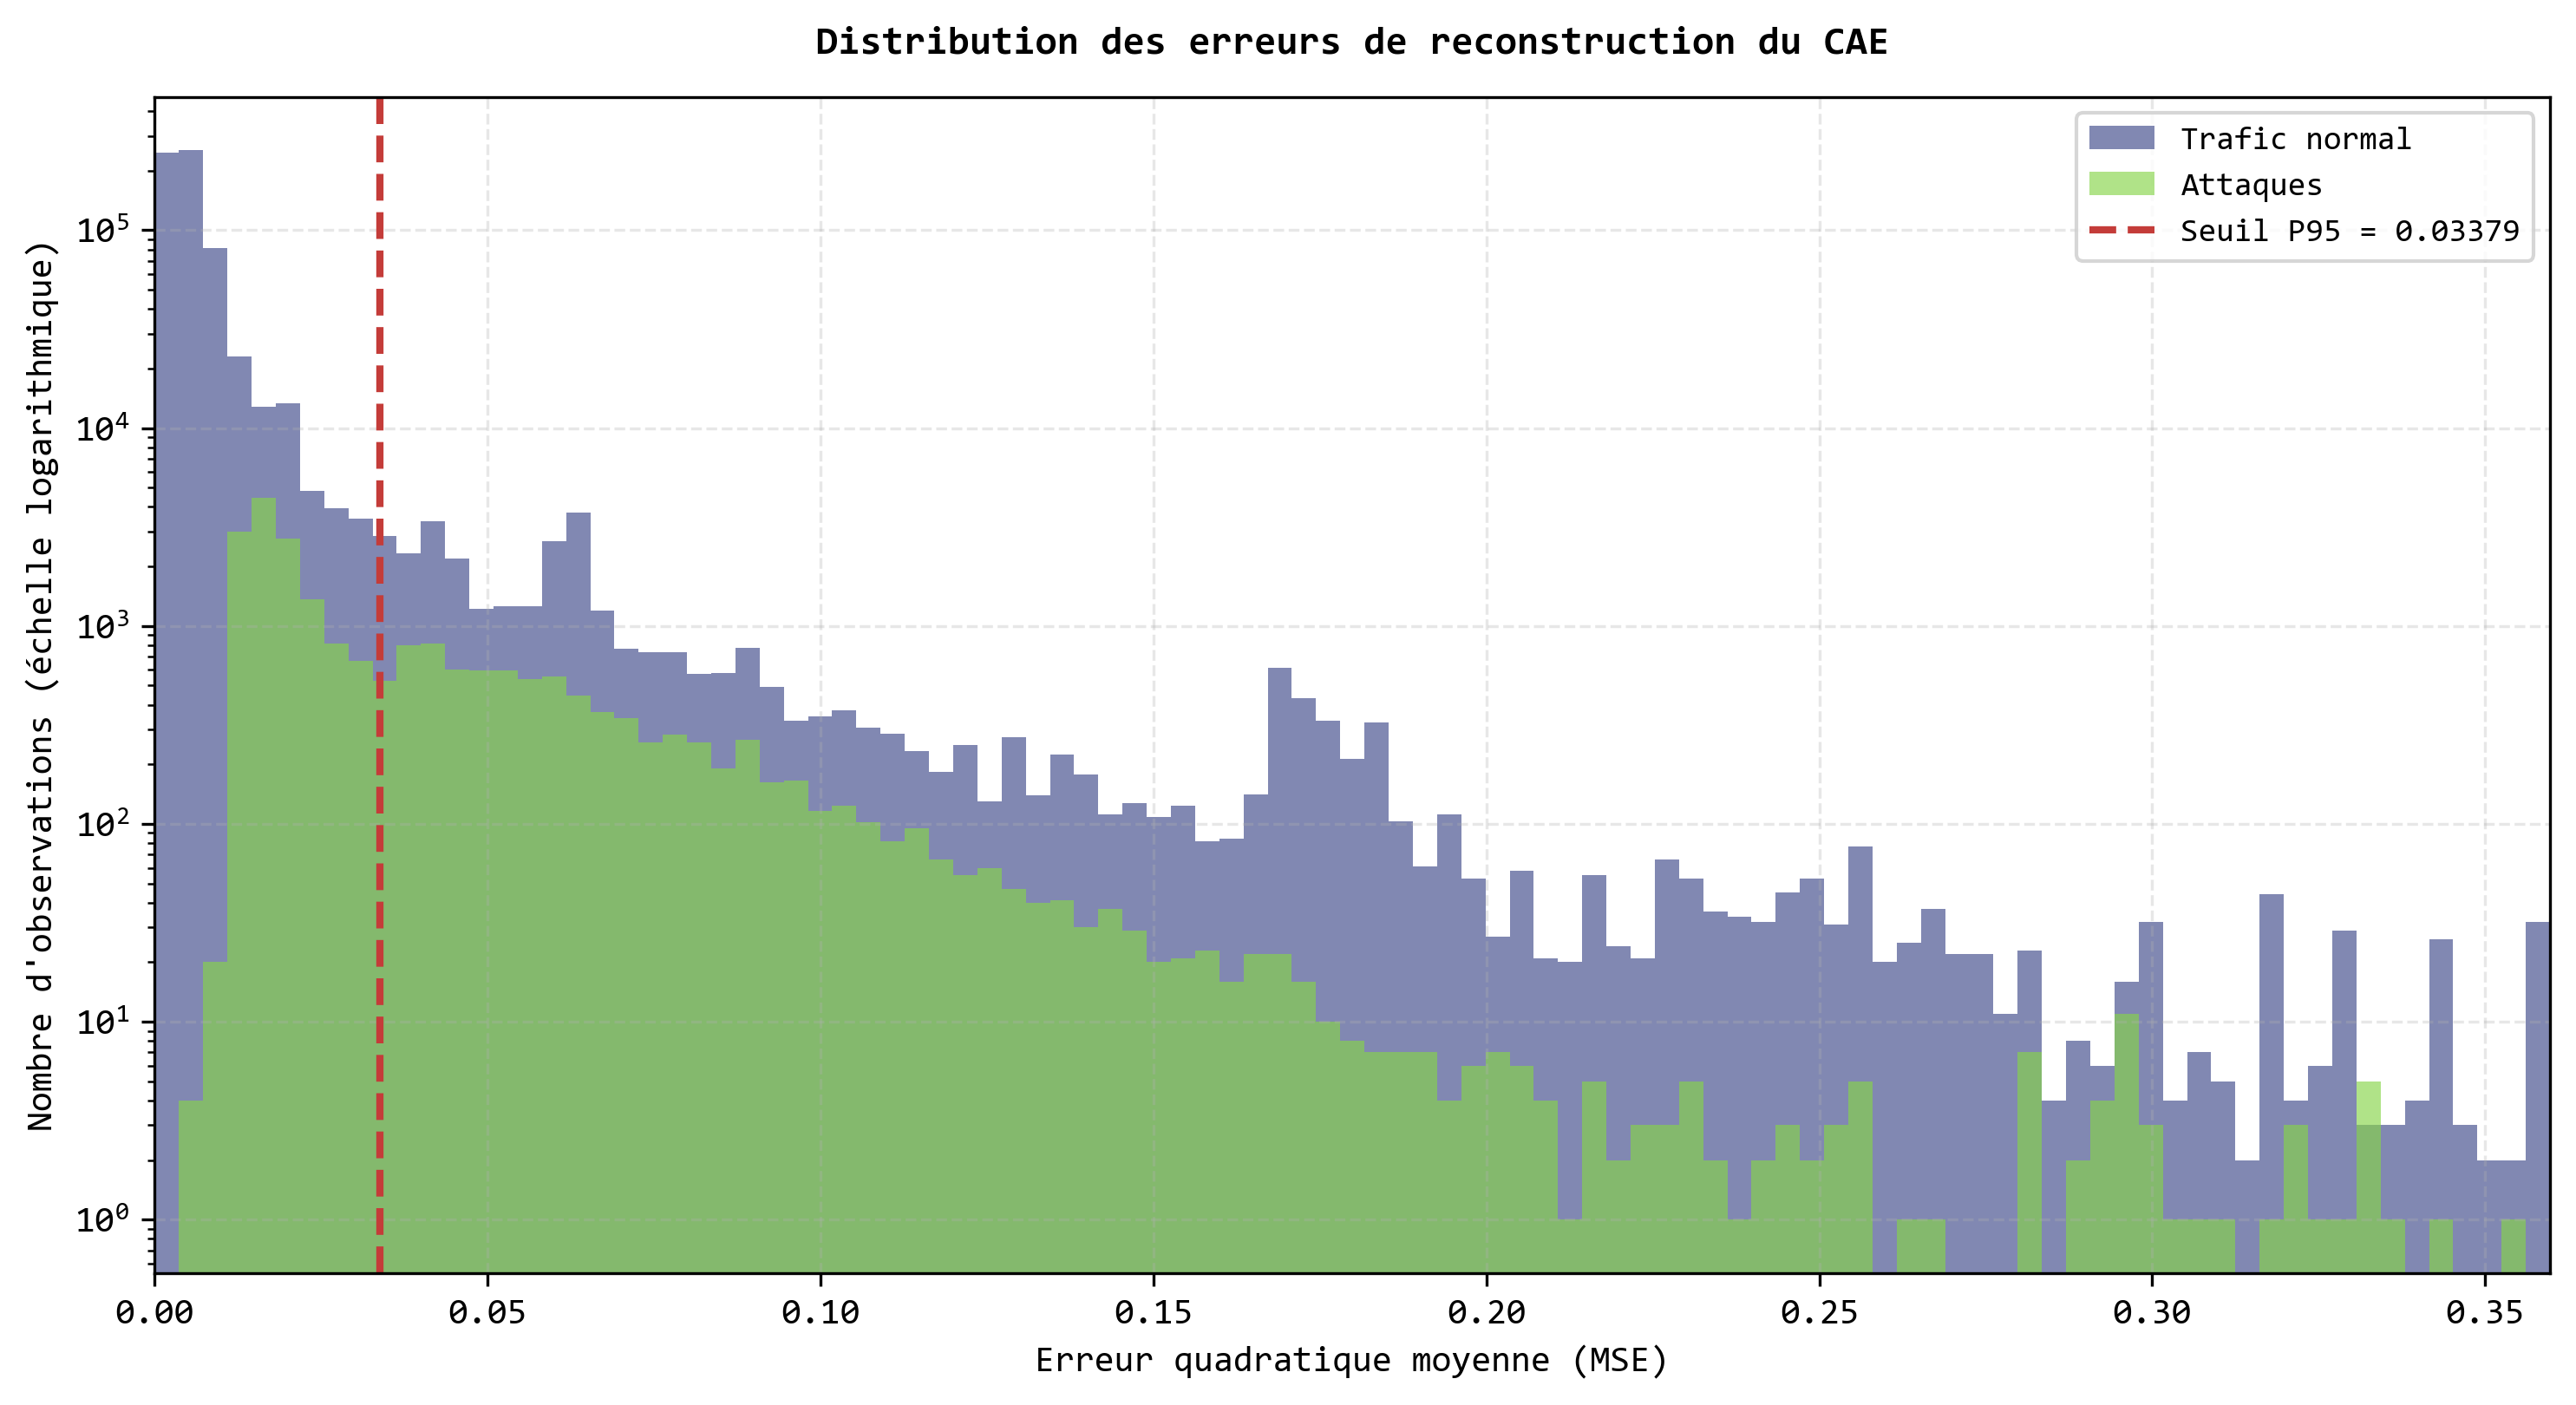

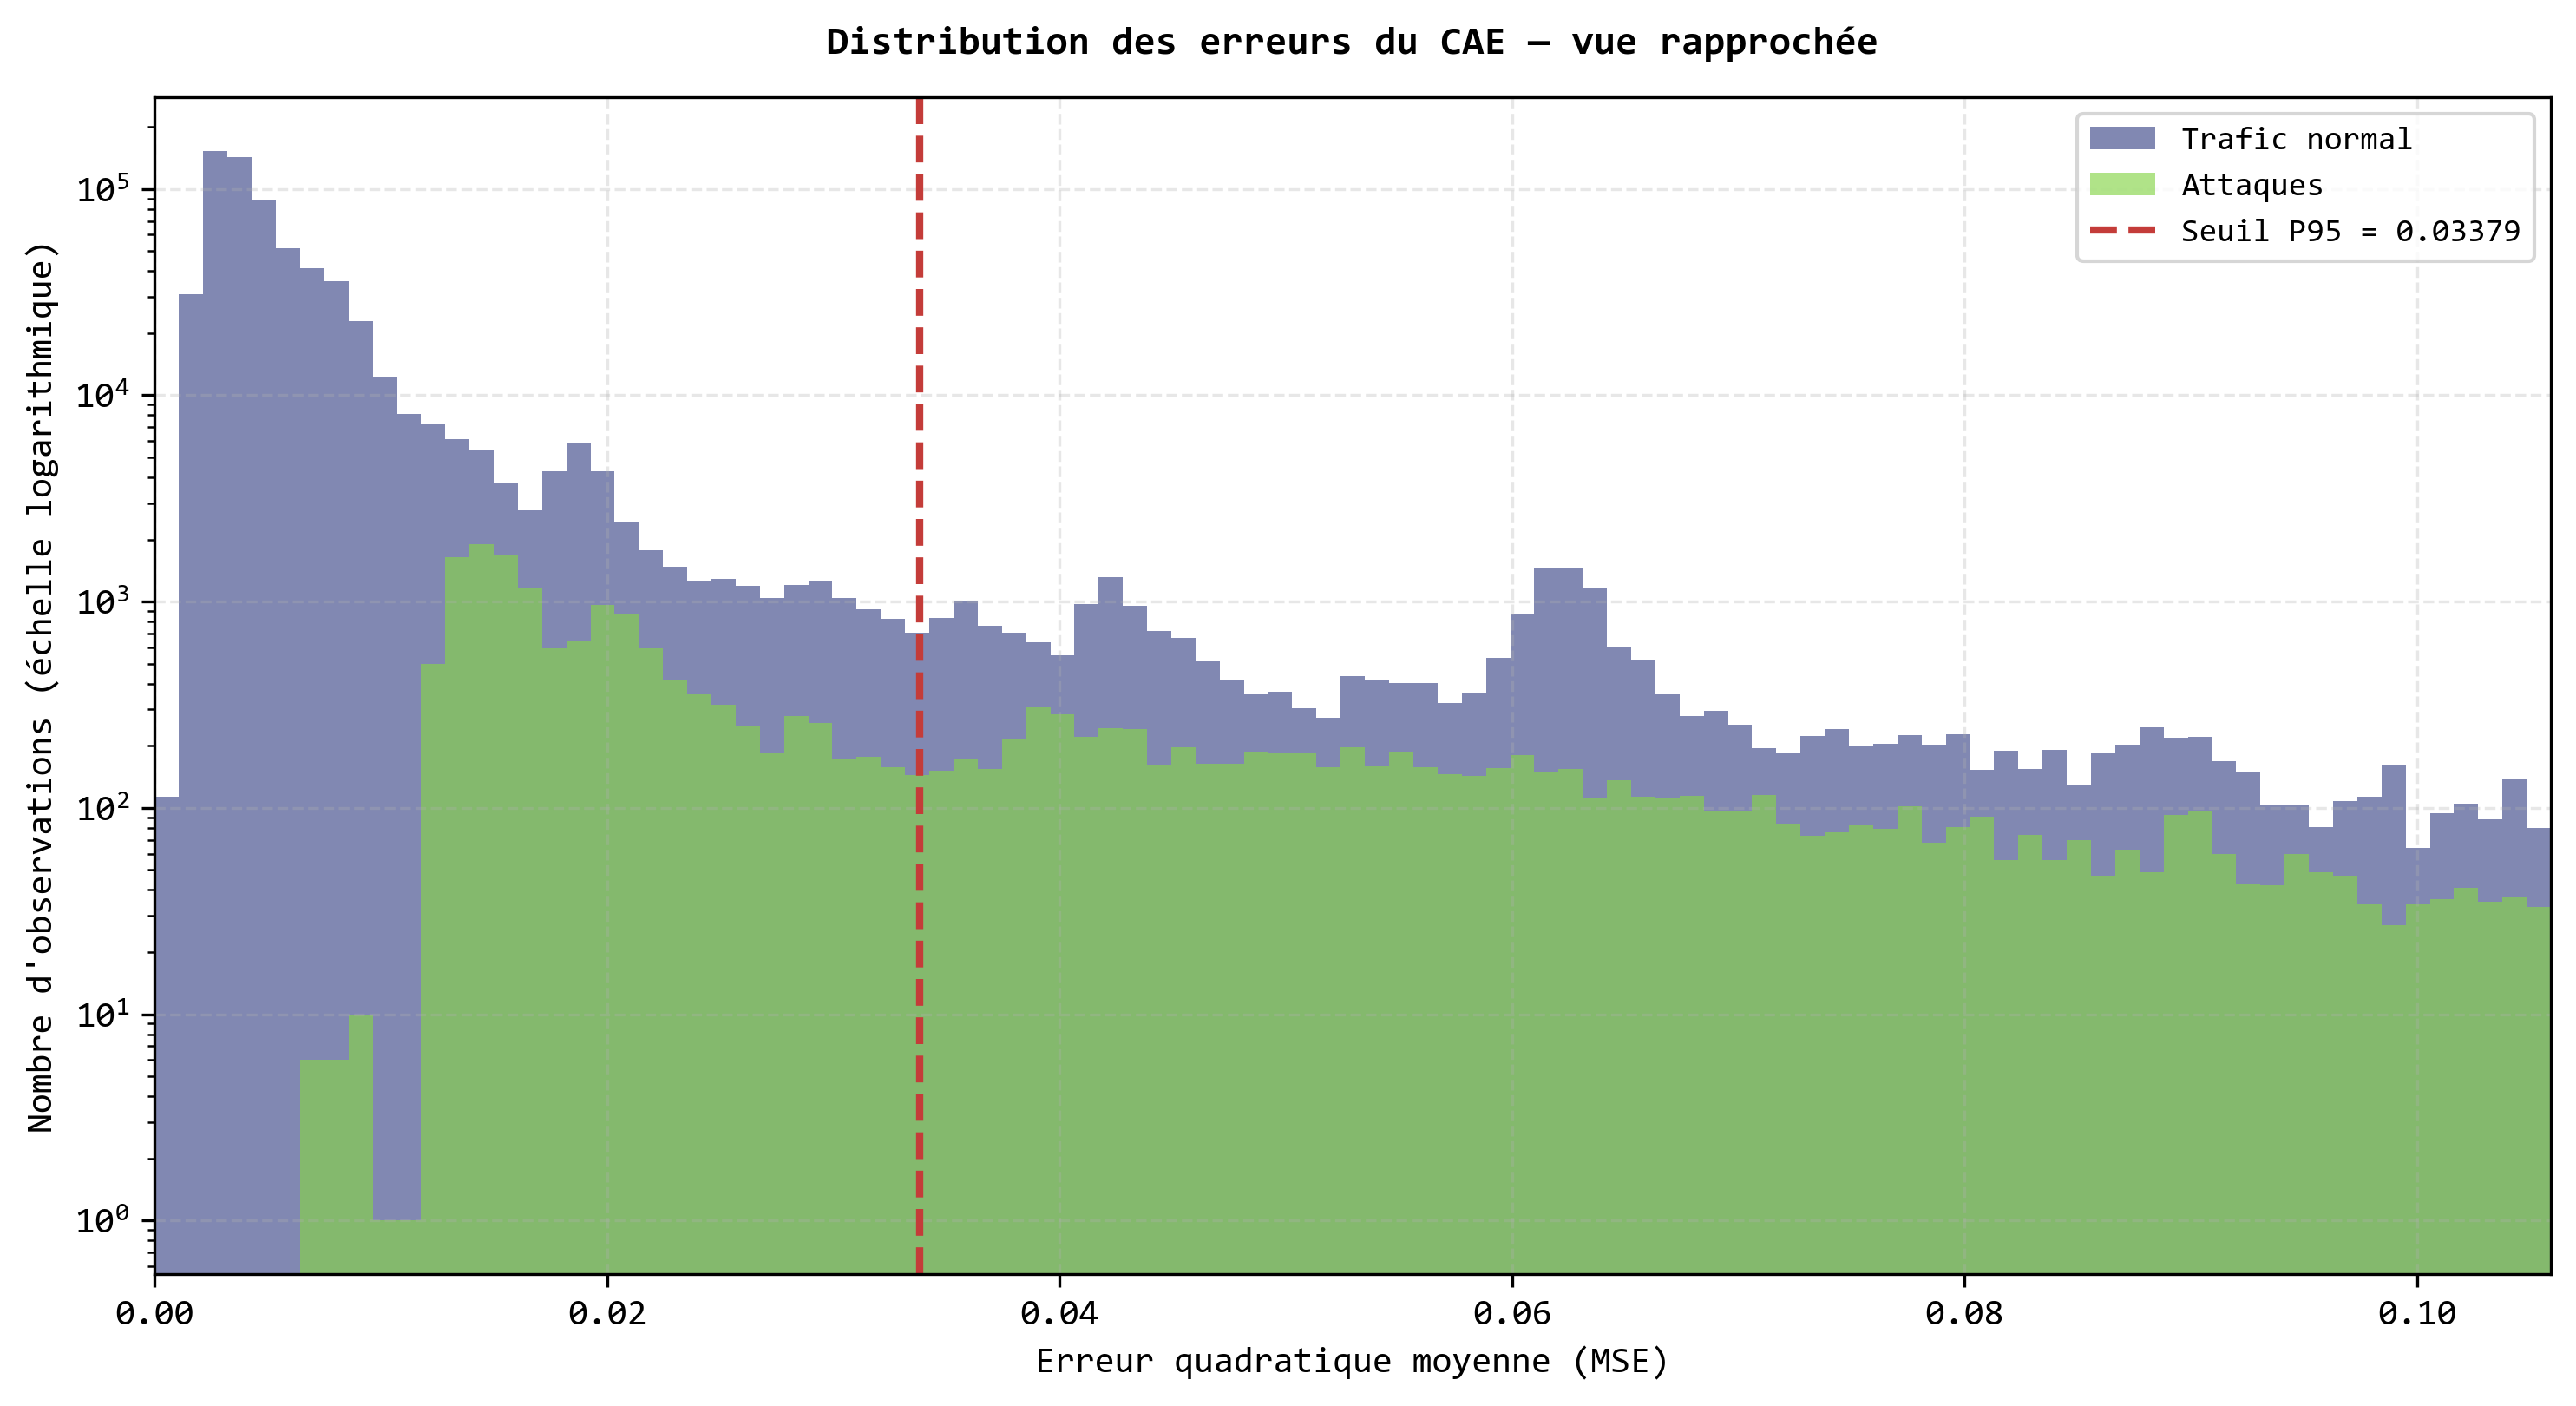


FIGURES CAE — EXPORT TERMINE
Figure generale : figures_corrigees_CAE\distribution_erreurs_CAE_corrigee.png
Figure zoom : figures_corrigees_CAE\distribution_erreurs_CAE_zoom_seuil.png
Scores sauvegardes : scores_historiques_CAE.npz
Protocole : exploratoire historique
Reentrainement : NON


In [14]:

# ============================================================
# CELLULE 39 — DISTRIBUTION DES SCORES DU CAE
# Correction demandee par le co-encadreur
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager
from pathlib import Path

# ------------------------------------------------------------
# 1. Recuperation des scores
# ------------------------------------------------------------

if "mse_error" not in globals():

    if "X_test" not in globals():
        raise RuntimeError(
            "X_test absent. Executer les cellules "
            "de preparation des donnees (2 a 9 et 16)."
        )

    if "cnn_autoencoder" not in globals():

        from tensorflow.keras.models import load_model

        model_path = Path(
            "CNN_Autoencoder_UNSW15.h5"
        )

        if not model_path.is_file():
            raise FileNotFoundError(
                "Modele sauvegarde introuvable : "
                + str(model_path)
            )

        cnn_autoencoder = load_model(
            model_path,
            compile=False
        )

    # Reconstruction par lots, sans entrainement
    X_pred_fig = cnn_autoencoder.predict(
        X_test,
        batch_size=256,
        verbose=1
    )

    mse_error = np.mean(
        np.square(X_test - X_pred_fig),
        axis=(1, 2)
    )

if "y_test" not in globals():
    raise RuntimeError(
        "y_test absent. Executer la cellule 16."
    )

scores = np.asarray(mse_error).ravel()
labels = np.asarray(y_test).ravel()

if len(scores) != len(labels):
    raise ValueError(
        "Les scores et les etiquettes "
        "n'ont pas la meme longueur."
    )

if not np.isfinite(scores).all():
    raise ValueError(
        "Scores MSE non finis detectes."
    )

if not np.isin(labels, [0, 1]).all():
    raise ValueError(
        "Les etiquettes doivent etre 0 ou 1."
    )

scores_normaux = scores[labels == 0]
scores_attaques = scores[labels == 1]

if not len(scores_normaux) or not len(scores_attaques):
    raise ValueError(
        "Une population normale ou attaque est vide."
    )

# Seuil du protocole exploratoire historique
# Recalcule selon la methode de la cellule 22

seuil_cae = float(
    np.percentile(scores_normaux, 95)
)

print(f"Observations normales : {len(scores_normaux):,}")
print(f"Observations attaques : {len(scores_attaques):,}")
print(f"Seuil historique P95 : {seuil_cae:.10f}")

# ------------------------------------------------------------
# 2. Presentation scientifique
# ------------------------------------------------------------

polices = {
    f.name for f in font_manager.fontManager.ttflist
}

police = (
    "Consolas"
    if "Consolas" in polices
    else "DejaVu Sans Mono"
)

plt.rcParams.update({
    "font.family": police,
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "savefig.dpi": 300
})

couleur_normal = plt.cm.viridis(0.22)
couleur_attaque = plt.cm.viridis(0.82)
couleur_seuil = "#C43C39"

dossier = Path("figures_corrigees_CAE")
dossier.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# 3. Definition des limites de visualisation
# ------------------------------------------------------------

# Vue generale couvrant au moins 99,9 %
# des scores de l'ensemble des observations.

limite_generale = max(
    float(np.quantile(scores, 0.999)),
    seuil_cae * 1.5
)

# Vue rapprochee de la zone de decision.

limite_zoom = max(
    seuil_cae * 2.5,
    float(np.quantile(scores_normaux, 0.99)),
    float(np.quantile(scores_attaques, 0.75))
)

limite_zoom = min(
    limite_zoom,
    limite_generale
)

# ------------------------------------------------------------
# 4. Fonction commune de representation
# ------------------------------------------------------------

def tracer_distribution(ax, limite, titre):

    bornes = np.linspace(
        0,
        limite,
        100
    )

    ax.hist(
        scores_normaux,
        bins=bornes,
        alpha=0.65,
        color=couleur_normal,
        label="Trafic normal",
        edgecolor="none"
    )

    ax.hist(
        scores_attaques,
        bins=bornes,
        alpha=0.65,
        color=couleur_attaque,
        label="Attaques",
        edgecolor="none"
    )

    ax.axvline(
        seuil_cae,
        color=couleur_seuil,
        linestyle="--",
        linewidth=2,
        label=f"Seuil P95 = {seuil_cae:.5f}"
    )

    ax.set_xlim(0, limite)

    ax.set_yscale("log")

    ax.set_xlabel(
        "Erreur quadratique moyenne (MSE)"
    )

    ax.set_ylabel(
        "Nombre d'observations (échelle logarithmique)"
    )

    ax.set_title(
        titre,
        fontweight="bold",
        pad=12
    )

    ax.grid(
        True,
        linestyle="--",
        alpha=0.3
    )

    ax.legend(
        fontsize=9
    )

# ------------------------------------------------------------
# 5. Figure 1 — Distribution generale
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(10, 5.5),
    dpi=300
)

tracer_distribution(
    ax,
    limite_generale,
    "Distribution des erreurs de reconstruction du CAE"
)

fig.tight_layout()

fichier_general = (
    dossier /
    "distribution_erreurs_CAE_corrigee.png"
)

fig.savefig(
    fichier_general,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 6. Figure 2 — Zoom autour du seuil
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(10, 5.5),
    dpi=300
)

tracer_distribution(
    ax,
    limite_zoom,
    "Distribution des erreurs du CAE — vue rapprochée"
)

fig.tight_layout()

fichier_zoom = (
    dossier /
    "distribution_erreurs_CAE_zoom_seuil.png"
)

fig.savefig(
    fichier_zoom,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 7. Sauvegarde des scores pour reproductibilite
# ------------------------------------------------------------

np.savez_compressed(
    dossier / "scores_historiques_CAE.npz",
    scores_mse=scores,
    etiquettes=labels,
    seuil_p95=np.array(seuil_cae)
)

# ------------------------------------------------------------
# 8. Bilan
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("FIGURES CAE — EXPORT TERMINE")
print("=" * 65)
print("Figure generale :", fichier_general)
print("Figure zoom :", fichier_zoom)
print("Scores sauvegardes : scores_historiques_CAE.npz")
print("Protocole : exploratoire historique")
print("Reentrainement : NON")
print("=" * 65)
